[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C08/E08-2_AI4I_maintenance_CORRIGE.ipynb)

# Panne d'une machine de production : faire voter des arbres indépendants

## Le contexte

Une machine de production est relevée toutes les quatre heures : températures ambiante et de palier, vitesse de rotation, couple, usure cumulée du palier, puissance absorbée et niveau de vibration. À chaque relevé, la machine s'est arrêtée sur panne ou non. Les pannes sont rares : 339 relevés sur 10 000. Le service maintenance voudrait les prévoir à partir des seules mesures du relevé, pour intervenir avant l'arrêt.

La grandeur à prédire est une catégorie, panne ou pas de panne : c'est un problème de classification binaire sur une classe rare. Les relevés se suivent dans le temps, donc la base de test est la dernière période, et non un tirage au hasard : on prédit le futur d'après le passé.

Défi : prédire `Panne` et obtenir un F-score macro supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est une forêt aléatoire aux réglages par défaut, qui fait voter une centaine d'arbres ; il atteint un F-score macro de 0,819 : à vous de faire mieux. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-AI4I_maintenance.xlsx`, dans le dossier `donnees` du dépôt : 10 000 relevés, 9 colonnes. Une ligne est un relevé, à intervalle de quatre heures.

| Colonne | Signification | Unité |
|---|---|---|
| `time` | instant du relevé, écarté des entrées | jours |
| `T_ambiant_C` | température ambiante | °C |
| `T_palier_C` | température du palier | °C |
| `Vitesse_rot_tr_min` | vitesse de rotation | tr/min |
| `Couple_Nm` | couple transmis | N·m |
| `Usure_palier_hrs` | usure cumulée du palier | h |
| `Puissance_W` | puissance absorbée | W |
| `Vibration_mm_s` | niveau de vibration | mm/s |
| `Panne` | cible : `1` si la machine s'est arrêtée sur panne, `0` sinon | 0 ou 1 |

Origine : jeu public transformé. Les températures sont converties en degrés Celsius, l'usure en heures, l'horodatage est ramené à un pas de quatre heures, la puissance et la vibration sont ajoutées, et les valeurs sont ajustées : il ne s'agit pas de lois physiques d'une machine réelle. Il enseigne une méthode, et aucune conclusion de maintenance n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides, l'ordre des relevés dans le temps et la rareté de la classe à prédire avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-AI4I_maintenance.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-AI4I_maintenance.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "Panne"
print("dimensions :", df.shape)
vides = df.isna().sum()
print("cases vides :", vides[vides > 0].to_dict())
print("relevés dans l'ordre du temps :", bool(df["time"].is_monotonic_increasing))
print(df[cible].value_counts().to_dict())
df.head(3)

dimensions : (10000, 9)
cases vides : {'T_palier_C': 196, 'Vitesse_rot_tr_min': 207, 'Vibration_mm_s': 177}
relevés dans l'ordre du temps : True
{0: 9661, 1: 339}


,time,T_ambiant_C,T_palier_C,Vitesse_rot_tr_min,Couple_Nm,Usure_palier_hrs,Puissance_W,Vibration_mm_s,Panne
0,0.0000,24.95,87.901235,1551.0,42.8,0.000000,6951.590560,2.496714,0
1,0.1667,25.05,88.518519,1408.0,46.3,0.050000,6826.722724,2.075174,0
2,0.3334,24.95,87.283951,1498.0,49.4,0.083333,7749.387543,3.003420,0


Lecture du résultat : 10 000 relevés, 9 colonnes, rangés dans l'ordre du temps. Trois colonnes ont des cases vides, qu'il faudra remplir : la température de palier (196), la vitesse de rotation (207) et la vibration (177). Seuls 339 relevés sont des pannes, soit 3,4 % : la classe à prédire est rare.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-AI4I_maintenance.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre la dernière période de côté

Les relevés se suivent dans le temps, et le modèle servira à prédire ce qui vient après ce qu'il a vu. Le quart le plus récent des relevés est donc mis de côté, avant tout apprentissage, tout réglage et toute comparaison avec la cible : un tirage au hasard mélangerait le passé et le futur, et le test ressemblerait trop à l'apprentissage. La coupure se fait sur l'instant, et deux relevés du même instant restent ensemble. La colonne `time` ne sert qu'à couper ; elle n'est pas une entrée du modèle.

In [2]:
import math

coupure = df["time"].sort_values(kind="stable").iloc[len(df) - math.ceil(0.25 * len(df))]
en_test = df["time"] >= coupure
X = df.drop(columns=[cible, "time"])
y = df[cible]
X_train, X_test = X[~en_test], X[en_test]
y_train, y_test = y[~en_test], y[en_test]
print(f"apprentissage : {len(X_train)} relevés, jusqu'au jour {coupure:.0f} exclu, dont {int(y_train.sum())} pannes")
print(f"test : {len(X_test)} relevés, à partir du jour {coupure:.0f}, dont {int(y_test.sum())} pannes")

apprentissage : 7500 relevés, jusqu'au jour 1250 exclu, dont 284 pannes
test : 2500 relevés, à partir du jour 1250, dont 55 pannes


### Étape 3 : le piège de l'exactitude

Un témoin qui répond toujours « pas de panne » ne détecte jamais rien. On compare son exactitude (part de réponses justes) et son F-score macro, qui compte la classe rare pour moitié.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

temoin = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
exactitude_temoin = accuracy_score(y_test, temoin.predict(X_test))
score_temoin = f1_score(y_test, temoin.predict(X_test), average="macro")
print(f"exactitude du témoin : {exactitude_temoin:.3f}")
print(f"F-score macro du témoin : {score_temoin:.3f}")

exactitude du témoin : 0.978
F-score macro du témoin : 0.494


Lecture du résultat : le témoin a une exactitude de 0,978, qui semble excellente, alors qu'il ne détecte aucune panne. Sur une classe rare, l'exactitude récompense l'inaction. Le F-score macro tombe à 0,494, puisqu'il compte la classe rare pour moitié : c'est lui qui est publié.

### Étape 4 : construire le modèle de départ

Le modèle de départ est celui de la section du livre : une forêt aléatoire, qui entraîne des arbres sur des tirages différents des relevés et des colonnes, puis fait voter leurs réponses. Il garde ses réglages par défaut, avec une graine fixée. Les cases vides sont remplies par la médiane de l'apprentissage. Il apprend sur `X_train` seul.

In [4]:
# Solution :
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

modele = make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(random_state=GRAINE))
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('randomforestclassifier',
                 RandomForestClassifier(random_state=42))])

### Étape 5 : mesurer sur la base de test

Le modèle prédit des relevés plus récents que tous ceux qu'il a vus. On lit le F-score macro, puis le rappel de la classe panne (part des pannes retrouvées), sa précision (part des alertes justes) et la matrice de confusion.

In [5]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

y_pred = modele.predict(X_test)
score_depart = f1_score(y_test, y_pred, average="macro")
rappel_depart = recall_score(y_test, y_pred)
precision_depart = precision_score(y_test, y_pred)
matrice = confusion_matrix(y_test, y_pred)
print(f"F-score macro : {score_depart:.3f}")
print(f"rappel de la classe panne : {rappel_depart:.3f}")
print(f"précision de la classe panne : {precision_depart:.3f}")
print("matrice de confusion (lignes : réel, colonnes : prédit ; pas de panne, panne)")
print(matrice)

F-score macro : 0.819
rappel de la classe panne : 0.527
précision de la classe panne : 0.829
matrice de confusion (lignes : réel, colonnes : prédit ; pas de panne, panne)
[[2439    6]
 [  26   29]]


Lecture du résultat : le F-score macro est de 0,819, bien au-dessus du témoin (0,494). Le détail est plus parlant. La précision est de 0,829 : 35 alertes, dont 6 fausses. Le rappel est de 0,527 : 29 pannes retrouvées sur 55, et 26 laissées passer. La forêt est prudente : 83 % de ses alertes sont justes, mais elle manque 47 % des pannes. C'est ce chiffre, mesuré sur une période que le modèle n'a jamais vue, que l'on a le droit d'annoncer.

## Pour aller plus loin : une variable d'effort, puis des feuilles plus larges

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les trois cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première cherche, sur l'apprentissage, où se concentrent les pannes : dans le temps, puis selon l'effort subi par le palier, produit de l'usure et du couple. La deuxième compare par validation croisée en blocs successifs, qui entraîne sur le passé et valide sur le bloc suivant, le modèle de départ, la forêt avec la variable d'effort, avec des feuilles d'au moins deux relevés et avec les classes équilibrées. Un gradient boosting, vu à la section suivante, est donné pour comparaison. La troisième mesure le modèle retenu une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

taux de pannes par cinquième de la période d'apprentissage (%) : [2.8, 2.1, 6.9, 5.2, 1.9]
taux de pannes par dixième de l'effort usure x couple (%) : [3.2, 3.1, 2.1, 1.6, 2.0, 1.5, 2.0, 2.9, 4.0, 15.5]


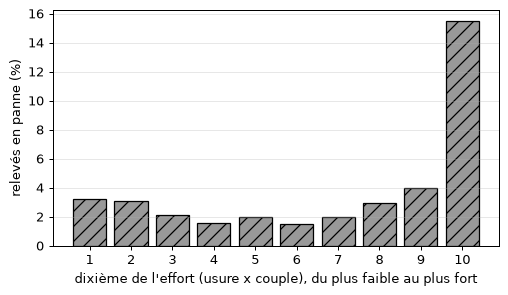

In [6]:
# Solution :
temps_train = df.loc[X_train.index, "time"]
par_periode = y_train.groupby(pd.qcut(temps_train, 5), observed=True).mean()
effort = X_train["Usure_palier_hrs"] * X_train["Couple_Nm"]
par_effort = y_train.groupby(pd.qcut(effort, 10), observed=True).mean()
print("taux de pannes par cinquième de la période d'apprentissage (%) :", (100 * par_periode).round(1).tolist())
print("taux de pannes par dixième de l'effort usure x couple (%) :", (100 * par_effort).round(1).tolist())

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(range(1, 11), 100 * par_effort.to_numpy(), color="0.6", edgecolor="black", hatch="//")
ax.set(xlabel="dixième de l'effort (usure x couple), du plus faible au plus fort", ylabel="relevés en panne (%)",
       xticks=range(1, 11))
ax.grid(alpha=0.3, axis="y")
plt.show()
# Fin de la solution

In [7]:
# Solution :
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import HistGradientBoostingClassifier

def ajouter_effort(X):
    X = X.copy()
    X["usure_x_couple"] = X["Usure_palier_hrs"] * X["Couple_Nm"]
    return X


def foret(**reglages):
    return make_pipeline(FunctionTransformer(ajouter_effort), SimpleImputer(strategy="median"),
                         RandomForestClassifier(random_state=GRAINE, **reglages))


blocs = TimeSeriesSplit(n_splits=5)
candidats = {
    "départ : forêt par défaut": modele,
    "forêt avec la variable d'effort": foret(),
    "forêt d'effort, feuilles d'au moins 2 relevés": foret(min_samples_leaf=2),
    "forêt d'effort, classes équilibrées": foret(class_weight="balanced_subsample")}
notes_cv = {}
for nom, pipeline in candidats.items():
    notes = cross_val_score(pipeline, X_train, y_train, cv=blocs, scoring="f1_macro")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : F-score macro {notes.mean():.3f} +/- {notes.std():.3f} sur 5 blocs")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
boosting = make_pipeline(FunctionTransformer(ajouter_effort), SimpleImputer(strategy="median"),
                         HistGradientBoostingClassifier(random_state=GRAINE))
notes = cross_val_score(boosting, X_train, y_train, cv=blocs, scoring="f1_macro")
print(f"pour comparaison, gradient boosting avec la variable d'effort : F-score macro {notes.mean():.3f} +/- {notes.std():.3f} sur 5 blocs")
# Fin de la solution

départ : forêt par défaut : F-score macro 0.767 +/- 0.065 sur 5 blocs
forêt avec la variable d'effort : F-score macro 0.812 +/- 0.088 sur 5 blocs
forêt d'effort, feuilles d'au moins 2 relevés : F-score macro 0.811 +/- 0.094 sur 5 blocs
forêt d'effort, classes équilibrées : F-score macro 0.750 +/- 0.094 sur 5 blocs
modèle retenu par la validation croisée : forêt avec la variable d'effort
pour comparaison, gradient boosting avec la variable d'effort : F-score macro 0.735 +/- 0.082 sur 5 blocs


In [8]:
# Solution :
retenu = candidats[nom_retenu].fit(X_train, y_train)
y_retenu = retenu.predict(X_test)
f1_retenu = f1_score(y_test, y_retenu, average="macro")
print(f"{nom_retenu}, mesuré une fois sur le test : F-score macro {f1_retenu:.3f}")
print(f"rappel {recall_score(y_test, y_retenu):.3f}, précision {precision_score(y_test, y_retenu):.3f}")
print(f"gain sur le modèle de départ : {f1_retenu - score_depart:+.3f}")
# Fin de la solution

forêt avec la variable d'effort, mesuré une fois sur le test : F-score macro 0.882
rappel 0.727, précision 0.816
gain sur le modèle de départ : +0.063


## Le score de référence

Le score publié est le F-score macro du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [9]:
import hashlib

score = f1_score(y_test, modele.predict(X_test), average="macro")
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE f1_macro = %.3f" % score)

EMPREINTE_TEST = f939b8b3da1b2a7006049c949b576473c0d60a9749a3976e45667d770e4c2807
SCORE_REFERENCE f1_macro = 0.819


## Synthèse

1. Des relevés qui se suivent dans le temps se découpent par la date : la base de test est la période la plus récente, jamais un tirage au hasard, et la validation croisée se fait en blocs successifs.
2. Sur une classe rare, l'exactitude récompense l'inaction ; le F-score macro, le rappel et la précision de la classe rare disent ce que le modèle détecte vraiment.
3. Une forêt aléatoire fait voter des arbres entraînés sur des tirages différents des relevés et des colonnes : le vote lisse la variance d'un arbre seul, mais ne crée pas d'information absente des colonnes.
4. Une variable construite à partir d'un constat sur l'apprentissage, ici l'effort subi par un palier usé, apporte ce que les arbres ne trouvent pas seuls avec 284 pannes à apprendre.
5. Le choix du modèle se fait par validation croisée sur l'apprentissage ; le test ne sert qu'une fois, au modèle retenu.